<a href="https://colab.research.google.com/github/hikaaru13/PCVK-GANJIL-TUGAS/blob/main/Week9_MuhammadAbitYusufAlghazaly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# Nomor 1: Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Nomor 2: Import Library Dasar
import cv2
import numpy as np
from matplotlib import pyplot as plt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


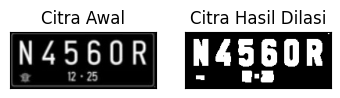

In [4]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# 4 Fungsi Dilasi Tanpa Library OpenCV
def dilasi_citra(F, w):
    # Ukuran citra
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structure Element Dilasi (SED)
    SED = np.ones((w, w), dtype=np.uint8)
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1 : i + constant1 + 1, j - constant1 : j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)
    return imgD

# Membaca citra dalam mode grayscale (0)
img_d = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)

# Thresholding dan pemanggilan fungsi dilasi
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w = 5
imgD = dilasi_citra(thresh, w)

# Menampilkan hasil
plt.subplot(131), plt.imshow(img_d, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(imgD, cmap='gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

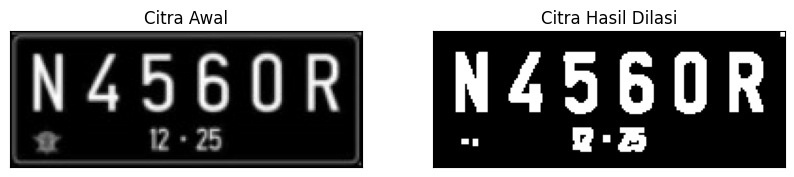

In [8]:
img = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg')
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

kernel = np.ones((3, 3), np.uint8)
dilasi = cv2.dilate(thresh, kernel, iterations=1)

# Visualisasi
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(dilasi, cv2.COLOR_BGR2RGB))
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

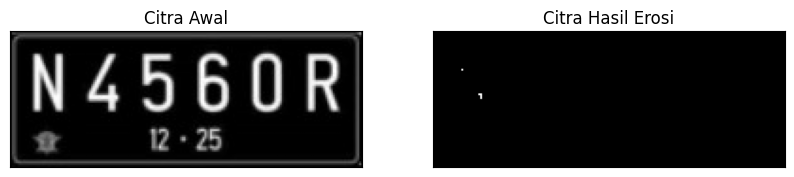

In [9]:
# Fungsi Erosi Citra Tanpa Library
def erosi_citra(F, k):
    m, n = F.shape
    SE = np.ones((k, k), dtype=np.uint8)
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[i - constant:i + constant + 1, j - constant:j + constant + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 175, 255, cv2.THRESH_BINARY)
k = 5

imgE = erosi_citra(thresh1, k)

# Visualisasi
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_e, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE, cmap='gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

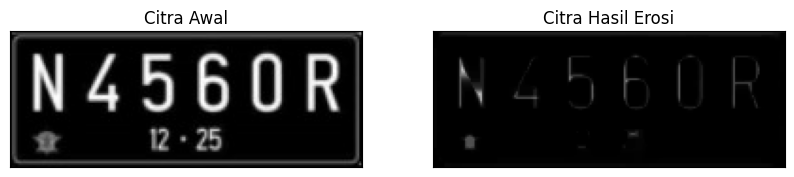

In [6]:
img = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg')
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(img, kernel, iterations=1)

# Visualisasi
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(cv2.cvtColor(erosion, cv2.COLOR_BGR2RGB))
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

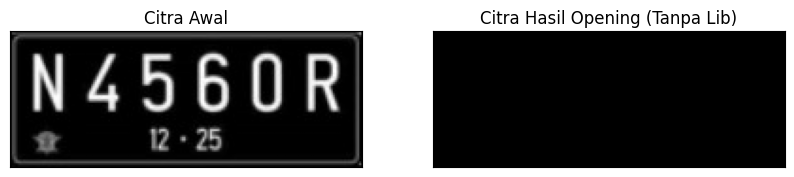

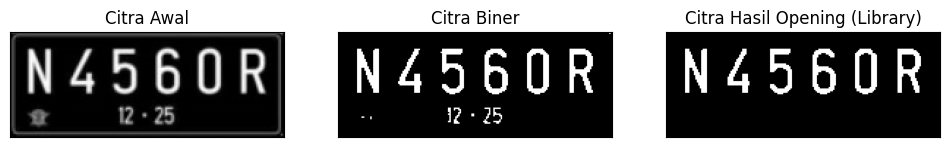

In [10]:
# --- Tanpa Library ---
img_o = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
reto, thresho = cv2.threshold(img_o, 127, 255, cv2.THRESH_BINARY)
k = 7

# Opening = Erosi lalu Dilasi
imgo = dilasi_citra(erosi_citra(thresho, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_o, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgo, cmap='gray')
plt.title('Citra Hasil Opening (Tanpa Lib)'), plt.xticks([]), plt.yticks([])
plt.show()

# --- Dengan Library ---
img = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
openn = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(openn, cmap='gray')
plt.title('Citra Hasil Opening (Library)'), plt.xticks([]), plt.yticks([])
plt.show()

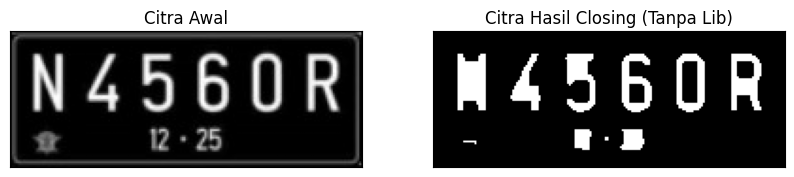

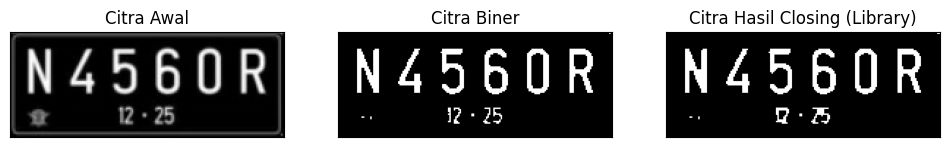

In [12]:
# --- Tanpa Library ---
img_c = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
retc, threshc = cv2.threshold(img_c, 127, 255, cv2.THRESH_BINARY)
k = 7

# Closing = Dilasi lalu Erosi
imgC = erosi_citra(dilasi_citra(threshc, k), k)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_c, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgC, cmap='gray')
plt.title('Citra Hasil Closing (Tanpa Lib)'), plt.xticks([]), plt.yticks([])
plt.show()

# --- Dengan Library ---
img = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
kernel = np.ones((3, 3), np.uint8)
closs = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))
plt.subplot(131), plt.imshow(img, cmap='gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132), plt.imshow(thresh, cmap='gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133), plt.imshow(closs, cmap='gray')
plt.title('Citra Hasil Closing (Library)'), plt.xticks([]), plt.yticks([])
plt.show()

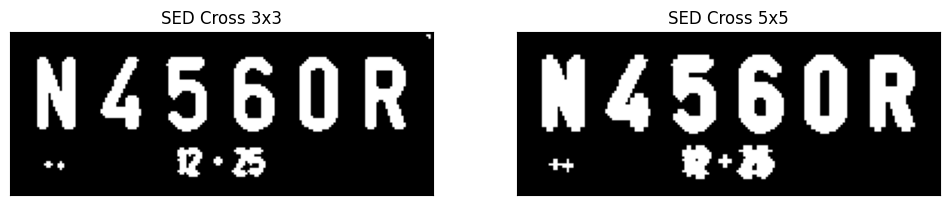

In [13]:
def dilasi_cross(F, SED, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

# 1. SED Cross 3x3
SED_cross3 = np.array([[0, 1, 0],
                       [1, 1, 1],
                       [0, 1, 0]], dtype=np.uint8)
imgD3 = dilasi_cross(thresh, SED_cross3, 3)

# 2. SED Cross 5x5
SED_cross5 = np.array([[0, 0, 1, 0, 0],
                       [0, 0, 1, 0, 0],
                       [1, 1, 1, 1, 1],
                       [0, 0, 1, 0, 0],
                       [0, 0, 1, 0, 0]], dtype=np.uint8)
imgD5 = dilasi_cross(thresh, SED_cross5, 5)

# Visualisasi
plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(imgD3, cmap='gray'), plt.title('SED Cross 3x3')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD5, cmap='gray'), plt.title('SED Cross 5x5')
plt.xticks([]), plt.yticks([])
plt.show()

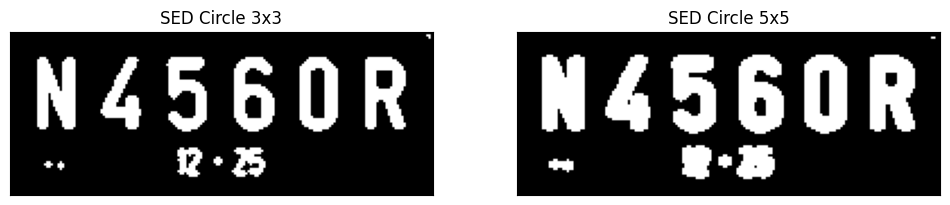

In [14]:
def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[i - constant1:i + constant1 + 1, j - constant1:j + constant1 + 1]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

img_d = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret, thresh = cv2.threshold(img_d, 127, 255, cv2.THRESH_BINARY)

# SED Circle 3x3 & 5x5
imgD_circle3 = dilasi_circular(thresh, 3)
imgD_circle5 = dilasi_circular(thresh, 5)

# Visualisasi
plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(imgD_circle3, cmap='gray'), plt.title('SED Circle 3x3')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgD_circle5, cmap='gray'), plt.title('SED Circle 5x5')
plt.xticks([]), plt.yticks([])
plt.show()

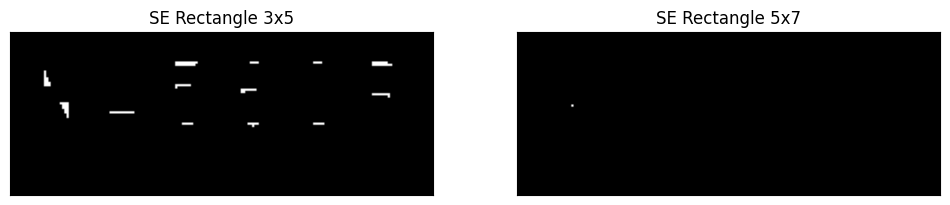

In [15]:
def erosi_rectangle(F, p_val, l_val):
    m, n = F.shape
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p_val, l_val))
    constant1 = (l_val - 1) // 2
    constant2 = (p_val - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant1, m - constant1):
        for j in range(constant2, n - constant2):
            temp = F[i - constant1:i + constant1 + 1, j - constant2:j + constant2 + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)

# 1. Rectangle 3x5 (p=5, l=3)
imgE_rect3x5 = erosi_rectangle(thresh1, 5, 3)

# 2. Rectangle 5x7 (p=7, l=5)
imgE_rect5x7 = erosi_rectangle(thresh1, 7, 5)

# Visualisasi
plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(imgE_rect3x5, cmap='gray'), plt.title('SE Rectangle 3x5')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_rect5x7, cmap='gray'), plt.title('SE Rectangle 5x7')
plt.xticks([]), plt.yticks([])
plt.show()


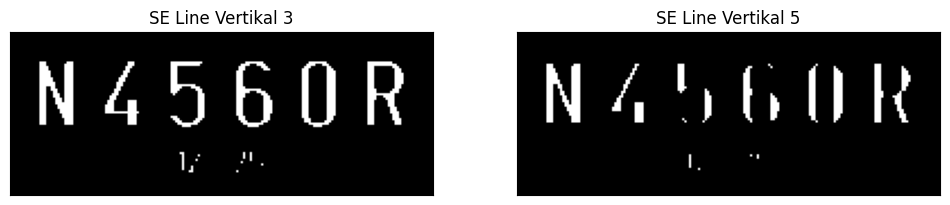

In [16]:
def erosi_line_vertikal(F, k):
    m, n = F.shape
    # Structuring Element Line Vertikal (1, k)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (1, k))
    constant = (k - 1) // 2
    imgE = np.zeros((m, n), dtype=np.uint8)

    for i in range(constant, m - constant):
        for j in range(n):
            temp = F[i - constant:i + constant + 1, j:j + 1]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE

img_e = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg', 0)
ret1, thresh1 = cv2.threshold(img_e, 127, 255, cv2.THRESH_BINARY)

imgE_line3 = erosi_line_vertikal(thresh1, 3)
imgE_line5 = erosi_line_vertikal(thresh1, 5)

# Visualisasi
plt.figure(figsize=(12, 5))
plt.subplot(121), plt.imshow(imgE_line3, cmap='gray'), plt.title('SE Line Vertikal 3')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(imgE_line5, cmap='gray'), plt.title('SE Line Vertikal 5')
plt.xticks([]), plt.yticks([])
plt.show()


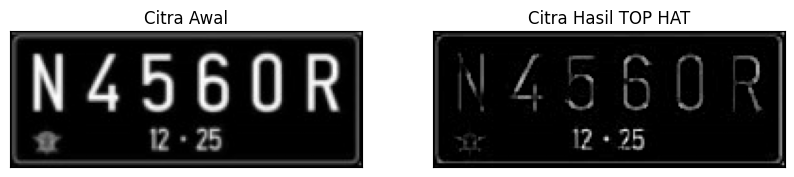

In [17]:
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

img = cv2.imread('/content/drive/MyDrive/PCVK/images/platnomor.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Top-Hat Transform
tophat_img = cv2.morphologyEx(img_gray, cv2.MORPH_TOPHAT, kernel)

# Visualisasi
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_gray, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(tophat_img, cmap='gray'), plt.title('Citra Hasil TOP HAT')
plt.xticks([]), plt.yticks([])
plt.show()

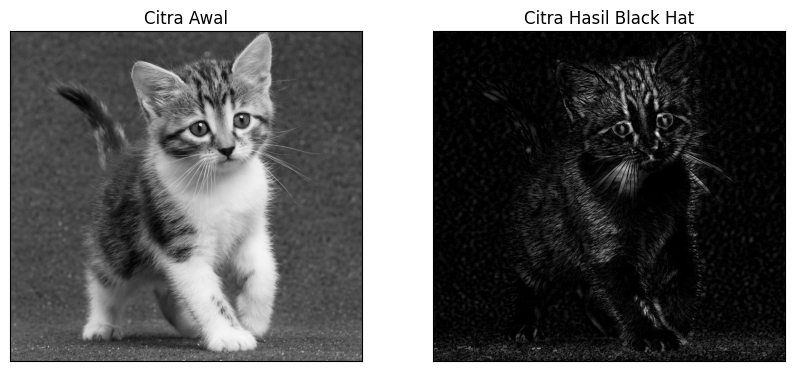

In [18]:

img = cv2.imread('/content/drive/MyDrive/PCVK/images/kitten01.jpg')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img_gray, cv2.MORPH_BLACKHAT, Kernel)

# Visualisasi
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img_gray, cmap='gray'), plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(blackhat, cmap='gray'), plt.title('Citra Hasil Black Hat')
plt.xticks([]), plt.yticks([])
plt.show()

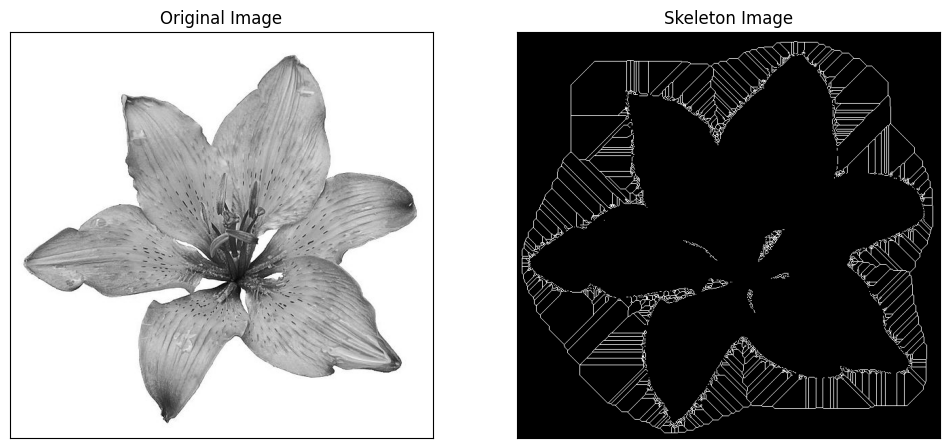

In [19]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# Read image
img = cv.imread('/content/drive/MyDrive/PCVK/images/lily.jpg', 0)
binary_img = img > filters.threshold_triangle(img)

# Convert boolean to 1 and 0
binary_cp = binary_img.copy().astype(int)

# Skeletonize
skeleton = skeletonize(binary_cp)

# Visualisasi
plt.figure(figsize=(12, 6))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.xticks([]), plt.yticks([])
plt.subplot(122), plt.imshow(skeleton, cmap='gray'), plt.title('Skeleton Image')
plt.xticks([]), plt.yticks([])
plt.savefig("binary_and_bin_skeleton.png")
plt.show()

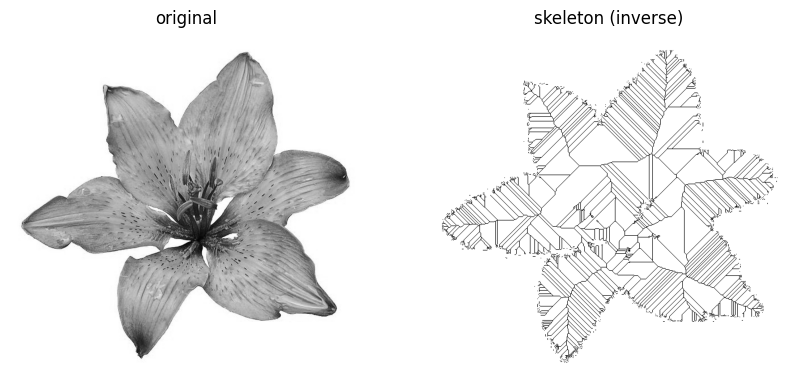

In [20]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/PCVK/images/lily.jpg', as_gray=True)

# Invert thresholding
binary = img < filters.threshold_triangle(img)

# Skeletonize
skeleton = skeletonize(binary)

# Visualisasi
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].axis('off')

ax[1].imshow(skeleton, cmap='gray_r')  # Reversely colormapped
ax[1].set_title('skeleton (inverse)')
ax[1].axis('off')

plt.show()

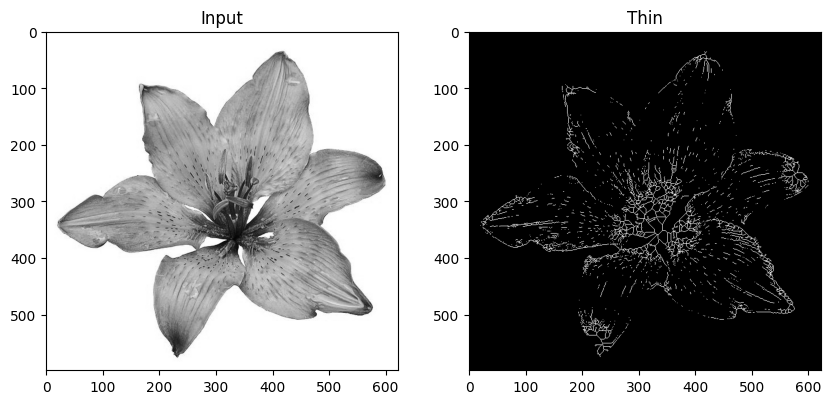

In [21]:
from skimage.util import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/images/lily.jpg')))
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 5))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')
ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')

plt.savefig('/tmp/char_out.png')
plt.show()